# Assignment 1 — South German Credit
Data Science for Business · 2026–2027

Student 1: Flioris Vassily r1142362


Complete this notebook in Python. Keep your code and relevant outputs here; write the report in `A1_Template.docx`. The full instructions are in `A1_Assignment.pdf`.

In Colab: upload this `.ipynb` to Drive, open it with **Google Colaboratory**, then click **Connect**. Upload `South_German_Credit.csv` through **Files**. Locally, keep the CSV in the working folder or update `DATA_PATH`.


## Problem Overview


As consultants at Leuven Analytics Experts & Partners (LAE), help a regional bank explore credit risk, build a logistic regression model and explain it through a scorecard.

**Dataset.** `South_German_Credit.csv` — 1,000 credit records from 1973–1975.
- 21 columns: 20 predictors + 1 target.
- 700 good credits, 300 bad credits.
- No missing values.

**Predictors.**
- 3 quantitative: `duration` (months), `amount` (after an undocumented monotonic transformation,
  so not interpretable in DM), `age` (years).
- 17 categorical: stored as numeric category codes (status, credit_history, purpose, savings,
  employment_duration, installment_rate, personal_status_sex, other_debtors, present_residence,
  property, other_installment_plans, housing, number_credits, job, people_liable, telephone,
  foreign_worker).

**Target.** `credit_risk` — 0 = bad credit, 1 = good credit.

**Deliverables.**
1. Explore the data and split it 70/30 (stratified).
2. Build a logistic regression using WOE-encoded predictors, evaluate with IV, ROC and AUC.
3. Construct a scorecard (600 points at 50:1 good:bad odds, 20 points to double the odds) and
   verify it against the model probabilities.

## 0. Load the dataset
Run the two cells below, then start Question 1.


In [89]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

# Add other imports as needed for your analysis.

In [90]:
DATA_PATH = Path("data/South_German_Credit.csv")
if not DATA_PATH.is_file():
    raise FileNotFoundError(
        "Upload South_German_Credit.csv to the Colab Files panel, "
        "or set DATA_PATH to the CSV location on your computer."
    )

credit = pd.read_csv(DATA_PATH)
display(credit.head())

,status,duration,credit_history,purpose,amount,savings,employment_duration,installment_rate,personal_status_sex,other_debtors,...,property,age,other_installment_plans,housing,number_credits,job,people_liable,telephone,foreign_worker,credit_risk
0,1,18,4,2,1049,1,2,4,2,1,...,2,21,3,1,1,3,2,1,2,1
1,1,9,4,0,2799,1,3,2,3,1,...,1,36,3,1,2,3,1,1,2,1
2,2,12,2,9,841,2,4,2,2,1,...,1,23,3,1,1,2,2,1,2,1
3,1,12,4,0,2122,1,3,3,3,1,...,1,39,3,1,2,2,1,1,1,1
4,1,12,4,0,2171,1,3,4,3,1,...,2,38,1,2,2,2,2,1,1,1


## 1. Explore the data

The bank wants to understand how applicant and loan characteristics relate to bad credit.

The goal here is to explore the data and explain one useful pattern before we touch any model.

#### 1. Load and check the data

Checks performd :
1. Load South_German_Credit.csv into your Python notebook. 
2. Check the dimensions, 
3. Check variable types, 
4. Check missing values, 
5. Check duplicate rows 
6. Check target counts. 
7. Create a modelling target with 1 = bad and 0 = good; keep the original credit_risk column. 
+ Record your checks and any action taken in the notebook.

In [91]:
# 1. loading (done in prev cell)

# 2. assert dim
print("Shape:", credit.shape)
assert credit.shape == (1000, 21), "Unexpected shape"

# 3. assert types
assert credit.dtypes.eq("int64").all(), f"Unexpected dtypes:\n{credit.dtypes}"

# 4. assery No missing values
assert credit.isna().sum().sum() == 0, "Missing values found"

# assert targ is strictly binary 0/1
assert set(credit["credit_risk"].unique()) == {0, 1}, "credit_risk not binary"

# 5. Duplicates — print the count once
dups = credit.duplicated().sum()  #returns bool if duplicates found
print("Duplicate rows:", dups)
assert dups == 0, f"Found {dups} duplicates — decide whether to drop or keep"

# 6. Target counts (700 good / 300 bad)
print("\ncredit_risk counts:\n", credit["credit_risk"].value_counts())
assert credit["credit_risk"].value_counts().to_dict() == {1: 700, 0: 300}, \
    "Target counts do not match the assignment (700 good / 300 bad)"

# 7. Modelling target: add a new column for bad credit, its the inverse of credit_risk
credit["bad"] = credit["credit_risk"].map({0: 1, 1: 0})     # map every value of initial credit_risk to its inverse within bad
assert credit["bad"].sum() == 300, "Expected 300 bad credits after flip"


Shape: (1000, 21)
Duplicate rows: 0

credit_risk counts:
 credit_risk
1    700
0    300
Name: count, dtype: int64


**Notes :**
- Shape is (1000,21) as expected.
- All columns are `int64`, even categorical variables.
- No duplicate rows. If yes the assert stops the codes and force us to deal with it.
- Target count : still 700 good and 300 bad credits.
- New column, "bad" with original `credit_risk` kept untouched.




#### 2. Keep a test sample separate

Before selecting predictors or exploring their relationship with the target, make a reproducible,
stratified 70% training / 30% test split. Record the random seed. Use this split throughout the
assignment: training data for exploration and model development, test data only for final
evaluation.

In [92]:
from sklearn.model_selection import train_test_split

SEED = 42

train, test = train_test_split(
    credit,
    test_size=0.30,
    stratify=credit["bad"],
    random_state=SEED,
)

print("Train shape:", train.shape)
print("Test shape:", test.shape)
print("\nTrain bad rate:", train["bad"].mean().round(4))
print("Test bad rate:", test["bad"].mean().round(4))

Train shape: (700, 22)
Test shape: (300, 22)

Train bad rate: 0.3
Test bad rate: 0.3


#### 3. Choose two variables and make one figure

Choose two variables and justify your choices. Define groups using the combination of both variables, grouping quantitative values or combining categories where appropriate. Make one clearly labelled figure showing each group's bad-credit rate and number of observations. Use descriptive category labels and explain your grouping choices.

#### 3.1 Variable typing

Before exploring relationships, I classify the predictors by their measurement type.
This classification is used later to decide how to group (Q1.3) and encode (Q2).

I define  4four groups:
- **Quantitative**: real measured values.
- **Binary categorical**: exactly two categories.
- **Ordinal categorical**: categories with a natural order.
- **Nominal categorical**: categories with no natural order.

In [93]:
quantitative_cols = [
    "duration",
    "amount",
    "age",
]

binary_categorical_cols = [
    "people_liable",
    "telephone",
    "foreign_worker",
]

ordinal_categorical_cols = [
    "status",                 # checking account balance, 1-none to 4-richest
    "credit_history",         # 0 past delays to 4 all repaid duly
    "savings",                # 1 none/unknown to 5 ≥ 1,000 DM
    "employment_duration",    # 1 unemployed to 5 ≥ 7 years
    "installment_rate",       # 1 ≥ 35% to 4 < 20% of income
    "present_residence",      # 1 < 1 year to 4 ≥ 7 years
    "property",               # 1 none to 4 real estate
    "number_credits",         # 1 = one credit to 4 = ≥ 6 credits
    "job",                    # 1 unskilled to 4 highly qualified
]

nominal_categorical_cols = [
    "purpose",
    "personal_status_sex",
    "other_debtors",
    "other_installment_plans",
    "housing",
]

categorical_cols = (
    binary_categorical_cols
    + ordinal_categorical_cols
    + nominal_categorical_cols
)

print("Quantitative:", len(quantitative_cols))
print("Binary:      ", len(binary_categorical_cols))
print("Ordinal:     ", len(ordinal_categorical_cols))
print("Nominal:     ", len(nominal_categorical_cols))
print("Total predictors:", len(quantitative_cols) + len(categorical_cols))

Quantitative: 3
Binary:       3
Ordinal:      9
Nominal:      5
Total predictors: 20


#### 3.2 EDA

1. Rank all variables using spread and monotonicity.
2. Re-group or re-combine variables if needed
3. Pick two from the top rankings and justify.
4. Make a graph 

**Spread :**
Spread is gonna help us see which variable explains the most the variance in the dataset (i.e. that separate "good creditor" form "bad" the best).

BUT :
- Low spread variables can be safely set aside, high-spread **ONLY** tells us we need to inspect it more.
- If a variable has the same bad rate as the original set (~30%), its spread is close to 0 and it doesn't carry any meaningful signal.
- spread a quick check but not enough alone (it only accounts the extreme values, not the middle ones, its also not comparable between variables with different level counts, and the extremes are often the smallest cells so a big spread can come from noise).
- we stay careful : spread is not "variance explained". It's just the range of the bad rate across levels. And a big spread doesn't mean the variable is good, it means it maybe it is.

**Monotonicity :**
Improves on the spread metric. Shows if the bad rate trends cleanly across ordered levels. A big spread with a broken middle (ex. like `duration` next cell) is less trustworthy than a big spread that goes cleanly up or down.
- It also shows 




In [94]:
def bad_rate_by_cat(df, col):
    """Bad rate and count per level. Rows ordered by level, NOT by bad rate."""
    tab = df.groupby(col)["bad"].agg(n="size", bad_rate="mean").reset_index()
    tab = tab.rename(columns={col: "level"})
    tab["level"] = tab["level"].astype(str)
    return tab.sort_values("level").reset_index(drop=True)

def bad_rate_by_quant(df, col, q=5):
    """Bad rate and count per quintile bin. Rows in bin order (which is natural)."""
    binned = pd.qcut(df[col], q=q, duplicates="drop")
    tab = df.groupby(binned)["bad"].agg(n="size", bad_rate="mean").reset_index()
    tab = tab.rename(columns={col: "level"})
    tab["level"] = tab["level"].astype(str)
    return tab

def spread_of(tab):
    return tab["bad_rate"].max() - tab["bad_rate"].min()


# -------------
rows = []
for col in categorical_cols:
    t = bad_rate_by_cat(train, col)
    if t["n"].min() >= 20:
        rows.append({"variable": col, "type": "categorical", "spread": spread_of(t)})

for col in quantitative_cols:
    t = bad_rate_by_quant(train, col)
    if t["n"].min() >= 20:
        rows.append({"variable": col, "type": "quantitative", "spread": spread_of(t)})

spreads = (
    pd.DataFrame(rows)
    .sort_values("spread", ascending=False)
    .reset_index(drop=True)
)
display(spreads)


# --------
top4 = spreads["variable"].head(4).tolist()

for col in top4:
    print(f"\n=== {col} ({'categorical' if col in categorical_cols else 'quantitative'}) ===")
    if col in categorical_cols:
        display(bad_rate_by_cat(train, col))
    else:
        display(bad_rate_by_quant(train, col))


# -----






,variable,type,spread
0,credit_history,categorical,0.507179
1,status,categorical,0.370364
2,other_debtors,categorical,0.292026
3,duration,quantitative,0.291545
4,savings,categorical,0.240234
5,property,categorical,0.235559
6,foreign_worker,categorical,0.200893
7,amount,quantitative,0.196584
8,employment_duration,categorical,0.180488
9,other_installment_plans,categorical,0.154999



=== credit_history (categorical) ===


,level,n,bad_rate
0,0,28,0.642857
1,1,38,0.552632
2,2,378,0.335979
3,3,57,0.298246
4,4,199,0.135678



=== status (categorical) ===


,level,n,bad_rate
0,1,193,0.492228
1,2,187,0.390374
2,3,41,0.195122
3,4,279,0.121864



=== other_debtors (categorical) ===


,level,n,bad_rate
0,1,639,0.300469
1,2,29,0.448276
2,3,32,0.156250



=== duration (quantitative) ===


,level,n,bad_rate
0,"(3.999, 12.0]",259,0.223938
1,"(12.0, 15.0]",50,0.180000
2,"(15.0, 24.0]",229,0.323144
3,"(24.0, 30.0]",39,0.282051
4,"(30.0, 72.0]",123,0.471545


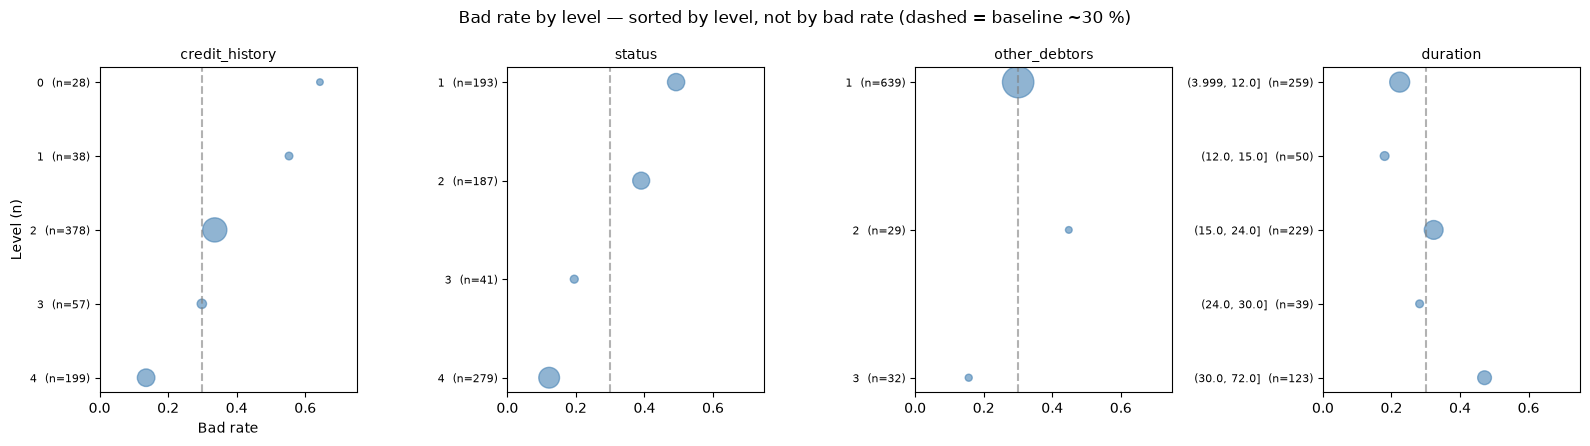

In [95]:
baseline = train["bad"].mean()
fig, axes = plt.subplots(1, len(top4), figsize=(4 * len(top4), 4.5), sharex=True)

for ax, col in zip(axes, top4):
    tab = bad_rate_by_cat(train, col) if col in categorical_cols else bad_rate_by_quant(train, col)

    y = list(range(len(tab)))
    ax.scatter(tab["bad_rate"], y, s=tab["n"] * 0.8, alpha=0.6, color="steelblue")
    ax.axvline(baseline, color="grey", linestyle="--", alpha=0.6, label="baseline")

    # y-axis: level name + n, so you can read every dot
    ax.set_yticks(y)
    ax.set_yticklabels([f"{lvl}  (n={n})" for lvl, n in zip(tab["level"], tab["n"])], fontsize=8)
    ax.set_title(col, fontsize=10)
    ax.set_xlim(0, 0.75)
    ax.invert_yaxis()   # first level at the top, like a table

axes[0].set_xlabel("Bad rate")
axes[0].set_ylabel("Level (n)")
fig.suptitle("Bad rate by level — sorted by level, not by bad rate (dashed = baseline ~30 %)")
plt.tight_layout()
plt.show()

Graph :
- the baseline at 30% represents the typical applicant. Below the baseline shows low-risk and above is high-risk.
- `credit_history`: is monotone, but assymetric, the high-risk side is small (~9%) compared to the low-risk.  

- `status` : monotone, no level sits on the baseline, symmetric and no tiny cell at the extremes.


- `other_debtors` : most population sits at baseline (~91%). Its spread comes form the 2 tiny cells at the extremes. 

- `duration` : also monotone, and symmetric. ts monotone slope is opposite to the ordinal categoricals, only because it has the opposite relation with risk (longer loan = higher risk).

#### 3.3 Variable choices


To illustrate, I choose the `credit_history` + `duration` variables :
- the bigger spread of `credit_history` and its assymetry makes it more interesting than `status`.
- `duration` is also a strong candidate, and this way we have One ordinal categorical + one quantitative to exercse both grouping techniques.


#### 3.4 Grouping choices

**Variable 1 - `credit_history`** :
- Categorical, ordinal — 5 codes (0–4) with a natural order.
- It has 4 categories (see `A1_Assignment.pdf`), we merge the ones with the same business meaning : 
- 0 (past delays) and 1 (critical account) --> both indicates previous problems.
- 2 (no credits / repaid duly) --> no credit history
- 3 and 4 --> both mean good history, reliable payer.


**Variable 2 - `duration`** :
- duration (quantitative) — bin into three business ranges, not five.
- Binned into 3 business ranges :
- Short ≤ 12 months
- Medium 13–24 months
- Long > 24 months

#### 3.5 Graph

In [96]:
# Grouping 
history_map = {0: "Previous problems", 1: "Previous problems",   # Group 0 and 1
                2: "No credit history",                         # No group
                3: "Reliable payer", 4: "Reliable payer"}      # group 3 and 4

def duration_bin(m):
    if m <= 12:   return "Short (≤12m)"
    elif m <= 24: return "Medium (13–24m)"
    else:         return "Long (>24m)"


In [97]:
# Graph
train["history_grp"]  = train["credit_history"].map(history_map)
train["duration_bin"] = train["duration"].apply(duration_bin)

group = (
    train
    .groupby(["history_grp", "duration_bin"])
    .agg(n=("bad", "size"), bad_rate=("bad", "mean"))
    .reset_index()
)
group["n_bad"] = (group["bad_rate"] * group["n"]).round().astype(int)

history_order  = ["Previous problems", "No credit history", "Reliable payer"]
duration_order = ["Short (≤12m)",     "Medium (13–24m)", "Long (>24m)"]
group["history_grp"]  = pd.Categorical(group["history_grp"],  categories=history_order,  ordered=True)
group["duration_bin"] = pd.Categorical(group["duration_bin"], categories=duration_order, ordered=True)
group = group.sort_values(["history_grp", "duration_bin"]).reset_index(drop=True)

group["label"] = group["history_grp"].astype(str) + "\n" + group["duration_bin"].astype(str)

#display(group)

clean = (
    group[["history_grp", "duration_bin", "n", "bad_rate", "n_bad"]]
    .copy()
)
clean["bad_rate"] = (clean["bad_rate"] * 100).round(1).astype(str) + " %"
clean = clean.rename(columns={
    "history_grp":  "History",
    "duration_bin": "Duration",
    "n":            "n",
    "bad_rate":     "Bad rate",
    "n_bad":        "Bad credits",
})
display(clean.reset_index(drop=True))



,History,Duration,n,Bad rate,Bad credits
0,Previous problems,Short (≤12m),19,57.9 %,11
1,Previous problems,Medium (13–24m),24,66.7 %,16
2,Previous problems,Long (>24m),23,52.2 %,12
3,No credit history,Short (≤12m),148,25.7 %,38
4,No credit history,Medium (13–24m),150,32.7 %,49
5,No credit history,Long (>24m),80,50.0 %,40
6,Reliable payer,Short (≤12m),92,9.8 %,9
7,Reliable payer,Medium (13–24m),105,17.1 %,18
8,Reliable payer,Long (>24m),59,28.8 %,17


Notes :
- This table combines the credit_history and the duration variables.
- ex. `Row 2` : creditors asking for a long-term loan and having bad payment history, 12/23 (~`52.2%`) failed on their payments
- ex. `Row 6` : creditors asking for a short-term loan and having good payment history, only 9/92 (~`9.8%`) failed on their payments

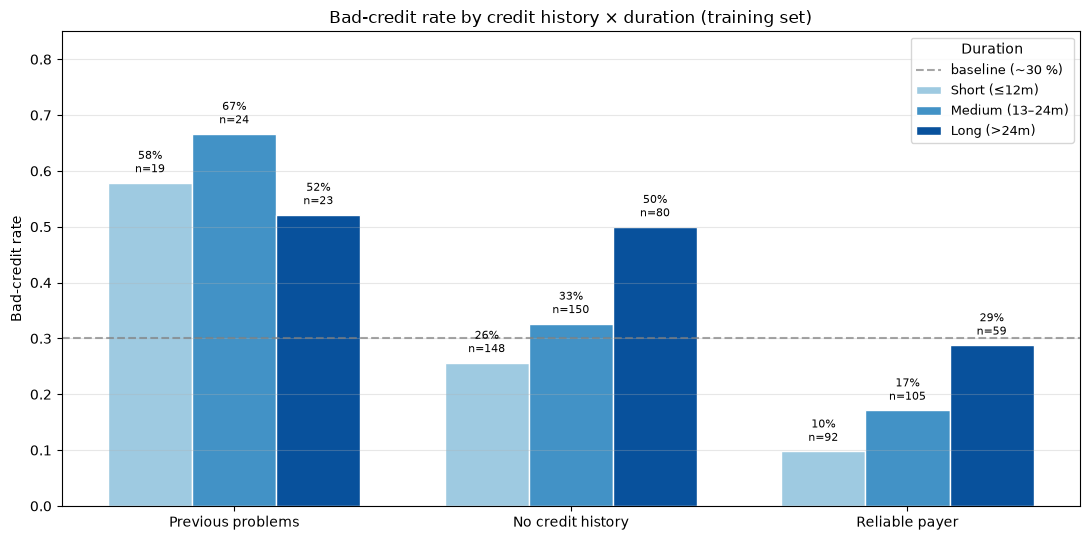

In [98]:
import matplotlib.pyplot as plt
import numpy as np

history_order  = ["Previous problems", "No credit history", "Reliable payer"]
duration_order = ["Short (≤12m)",     "Medium (13–24m)", "Long (>24m)"]

# consistent palette per duration bin (light → dark blue = short → long)
colors = {"Short (≤12m)": "#9ecae1", "Medium (13–24m)": "#4292c6", "Long (>24m)": "#08519c"}

fig, ax = plt.subplots(figsize=(11, 5.5))

n_hist   = len(history_order)
n_dur    = len(duration_order)
bar_w    = 0.25
x_center = np.arange(n_hist)

for j, dur in enumerate(duration_order):
    sub = group[group["duration_bin"].astype(str) == dur].set_index("history_grp")
    sub = sub.reindex(history_order)
    x   = x_center + (j - 1) * bar_w       # -1, 0, +1 offset
    bars = ax.bar(x, sub["bad_rate"], width=bar_w,
                  color=colors[dur], edgecolor="white", label=dur)

    for b, rate, n in zip(bars, sub["bad_rate"], sub["n"]):
        ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.012,
                f"{rate:.0%}\nn={int(n)}",
                ha="center", va="bottom", fontsize=8)

ax.axhline(train["bad"].mean(), color="grey", linestyle="--", alpha=0.7, label="baseline (~30 %)")
ax.set_xticks(x_center)
ax.set_xticklabels(history_order, fontsize=10)
ax.set_ylabel("Bad-credit rate")
ax.set_ylim(0, 0.85)
ax.set_title("Bad-credit rate by credit history × duration (training set)")
ax.legend(title="Duration", loc="upper right", fontsize=9)
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


#### 4. Interpret the evidence

Identify the group with the highest bad-credit rate and the group containing the most bad credits. Discuss the reliability of the pattern, considering group sizes and your grouping choices. Give one useful takeaway for the bank.

In [99]:
top_rate   = group.sort_values("bad_rate", ascending=False).iloc[0]
top_volume = group.sort_values("n_bad",     ascending=False).iloc[0]

def as_row(s, tag):
    return pd.DataFrame([{
        "Pick":           tag,
        "History":        s["history_grp"],
        "Duration":       s["duration_bin"],
        "n":              int(s["n"]),
        "Bad credits":    int(s["n_bad"]),
        "Bad rate":       f"{s['bad_rate']:.1%}",
    }])

comparison = pd.concat([as_row(top_rate,   "Highest bad-rate"), as_row(top_volume, "Largest bad-credit volume")], ignore_index=True,)

display(comparison)

,Pick,History,Duration,n,Bad credits,Bad rate
0,Highest bad-rate,Previous problems,Medium (13–24m),24,16,66.7%
1,Largest bad-credit volume,No credit history,Medium (13–24m),150,49,32.7%


Reliability : 
- The `highest bad rate` group (`row 0`) has a very small population (n=24), but has x2 higher rates (2/3).
- The `largest bad-credit volume` (`row 1`) has a bigger population (n=150), but has a lower bad rate (1/3).
- So the volume row is much more reliable, having a way bigger population count (`x6`). The highest rate row is noisier.

Takeaway for the bank : 
- The group for the bank to target depends on cost, how expensive is a bad loan to the bank versus reviewing appplicants.
- If reviews are cheap and bad loans expensive then it is better to target the big group, 49 bad loans avoided is better than 16, even if the rate is lower.
- The small group has a higher rate (2/3) but it's only 24 people, so the bank that only chases the highest rate is not looking for the most profitable answer.


Note :
- Why did both landed on the `medium` loan duration ? This is simply because more people choose for a medium-term loan (total n is 279).



---

## 2. Build and evaluate the model

Select predictors and use WOE to build and assess one logistic regression model for bad credit.




### 2.1 Select and transform your predictors

Binning strategy
- for our binning strategy, I follow Dimitri Bianco's method (https://www.youtube.com/watch?v=T__iiWXYam4).
- He showed a bottom-up binning strategy, where we start with fine bines and then iteratively merge adjacent bins until meeting a monotonic WoE, big enough cell sizes and maximizing IV.
- 


Merging strategy :
1. merge bins with n<35 with the closest WoE-noeighbor.
2. merge zigzags, when WoE goes up and down by more than 0.15, the middle bin is noise and we merge with its closest WoE.
3. try to keep 2-4 bins minimum.
4. Increase for monotone WoE
5. drop variables with IV < 0.02

In [100]:
def woe_stats(df, col, target="bad", bins=None, bin_edges=None):
    """
    df        : training df
    col       : column to inspect
    bins      : optional Series of pre-assigned bins (for categorical — raw codes)
    bin_edges : optional list of numeric edges (for quantitative — custom cuts)
    If both bins and bin_edges are None, uses 10 quantile bins.
    """
    d = df.copy()
    if bins is not None:
        d["_bin"] = bins.values
    elif bin_edges is not None:
        d["_bin"] = pd.cut(d[col], bins=bin_edges, duplicates="drop")
    else:
        d["_bin"] = pd.qcut(d[col], q=10, duplicates="drop")

    tab = (d.groupby("_bin", observed=True)[target]
             .agg(n="size", bads="sum")
             .reset_index())
    tab["goods"]      = tab["n"] - tab["bads"]
    tab["bad_rate"]   = tab["bads"] / tab["n"]
    tab["goods_p"]    = tab["goods"] / tab["goods"].sum()
    tab["bads_p"]     = tab["bads"]  / tab["bads"].sum()
    tab["woe"]        = np.log((tab["goods_p"] + 1e-6) / (tab["bads_p"] + 1e-6))
    tab["iv_contrib"] = (tab["goods_p"] - tab["bads_p"]) * tab["woe"]

    # sort by the natural order of the bin (interval left / code value)
    if bins is not None:
        tab = tab.sort_values("_bin").reset_index(drop=True)
    else:
        tab = tab.sort_values("_bin").reset_index(drop=True)

    total_iv = tab["iv_contrib"].sum()
    return tab, total_iv

#### RAW BINS

In [101]:
print("=" * 80)
print("QUANTITATIVE")
print("=" * 80)
for col in ["duration", "amount", "age"]:
    tab, iv = woe_stats(train, col)
    print(f"\n### {col}  —  IV (10 deciles) = {iv:.3f}")
    display(tab[["_bin", "n", "bads", "bad_rate", "goods_p", "bads_p", "woe", "iv_contrib"]]
              .round(4)
              .rename(columns={"_bin": "bin"}))

print("\n" + "=" * 80)
print("ORDINAL CATEGORICAL — raw codes, look for adjacent codes with close WOE")
print("=" * 80)
for col in ["status", "credit_history", "savings", "employment_duration",
            "installment_rate", "present_residence", "property",
            "number_credits", "job"]:
    tab, iv = woe_stats(train, col, bins=train[col])
    print(f"\n### {col}  —  IV (raw codes) = {iv:.3f}")
    display(tab[["_bin", "n", "bads", "bad_rate", "goods_p", "bads_p", "woe", "iv_contrib"]]
              .round(4)
              .rename(columns={"_bin": "code"}))

QUANTITATIVE

### duration  —  IV (10 deciles) = 0.288


,bin,n,bads,bad_rate,goods_p,bads_p,woe,iv_contrib
0,"(3.999, 8.0]",72,8,0.1111,0.1306,0.0381,1.2321,0.1140
1,"(8.0, 12.0]",187,50,0.2674,0.2796,0.2381,0.1607,0.0067
2,"(12.0, 15.0]",50,9,0.1800,0.0837,0.0429,0.6690,0.0273
3,"(15.0, 18.0]",74,30,0.4054,0.0898,0.1429,-0.4643,0.0246
4,"(18.0, 24.0]",155,44,0.2839,0.2265,0.2095,0.0780,0.0013
5,"(24.0, 30.0]",39,11,0.2821,0.0571,0.0524,0.0870,0.0004
6,"(30.0, 36.0]",66,28,0.4242,0.0776,0.1333,-0.5419,0.0302
7,"(36.0, 72.0]",57,30,0.5263,0.0551,0.1429,-0.9526,0.0836



### amount  —  IV (10 deciles) = 0.123


,bin,n,bads,bad_rate,goods_p,bads_p,woe,iv_contrib
0,"(249.999, 950.9]",70,24,0.3429,0.0939,0.1143,-0.1967,0.0040
1,"(950.9, 1275.0]",72,19,0.2639,0.1082,0.0905,0.1786,0.0032
2,"(1275.0, 1482.2]",68,16,0.2353,0.1061,0.0762,0.3314,0.0099
3,"(1482.2, 1870.0]",70,17,0.2429,0.1082,0.0810,0.2898,0.0079
4,"(1870.0, 2278.5]",70,18,0.2571,0.1061,0.0857,0.2136,0.0044
5,"(2278.5, 2780.2]",70,18,0.2571,0.1061,0.0857,0.2136,0.0044
6,"(2780.2, 3513.8]",70,17,0.2429,0.1082,0.0810,0.2898,0.0079
7,"(3513.8, 4587.4]",70,20,0.2857,0.1020,0.0952,0.0690,0.0005
8,"(4587.4, 7119.8]",70,28,0.4000,0.0857,0.1333,-0.4418,0.0210
9,"(7119.8, 18424.0]",70,33,0.4714,0.0755,0.1571,-0.7329,0.0598



### age  —  IV (10 deciles) = 0.138


,bin,n,bads,bad_rate,goods_p,bads_p,woe,iv_contrib
0,"(18.999, 24.0]",98,37,0.3776,0.1245,0.1762,-0.3473,0.0180
1,"(24.0, 26.0]",59,22,0.3729,0.0755,0.1048,-0.3274,0.0096
2,"(26.0, 28.0]",62,19,0.3065,0.0878,0.0905,-0.0305,0.0001
3,"(28.0, 31.0]",80,29,0.3625,0.1041,0.1381,-0.2828,0.0096
4,"(31.0, 34.0]",74,24,0.3243,0.1020,0.1143,-0.1133,0.0014
5,"(34.0, 36.0]",59,9,0.1525,0.1020,0.0429,0.8675,0.0513
6,"(36.0, 40.0]",72,18,0.2500,0.1102,0.0857,0.2513,0.0062
7,"(40.0, 45.0]",64,17,0.2656,0.0959,0.0810,0.1696,0.0025
8,"(45.0, 52.0]",66,12,0.1818,0.1102,0.0571,0.6568,0.0348
9,"(52.0, 75.0]",66,23,0.3485,0.0878,0.1095,-0.2216,0.0048


... (14 outputs left out)


### number_credits  —  IV (raw codes) = 0.014


,code,n,bads,bad_rate,goods_p,bads_p,woe,iv_contrib
0,1,445,140,0.3146,0.6224,0.6667,-0.0686,0.0030
1,2,235,66,0.2809,0.3449,0.3143,0.0929,0.0028
2,3,16,3,0.1875,0.0265,0.0143,0.6190,0.0076
3,4,4,1,0.2500,0.0061,0.0048,0.2513,0.0003



### job  —  IV (raw codes) = 0.016


,code,n,bads,bad_rate,goods_p,bads_p,woe,iv_contrib
0,1,16,4,0.2500,0.0245,0.0190,0.2513,0.0014
1,2,137,37,0.2701,0.2041,0.1762,0.1470,0.0041
2,3,440,131,0.2977,0.6306,0.6238,0.0108,0.0001
3,4,107,38,0.3551,0.1408,0.1810,-0.2508,0.0101


#### LEVELLED BINS

In [102]:
def duration_bin4(m):
    if   m <= 8:  return "Very short (≤8m)"
    elif m <= 15: return "Short (9–15m)"
    elif m <= 30: return "Medium (16–30m)"
    else:         return "Long (>30m)"

def amount_bin2(x):
    return "Low–mid (≤4587)" if x <= 4587 else "High (>4587)"

def age_bin2(a):
    return "Young (≤34)" if a <= 34 else "Older (≥35)"

history_map_v2 = {
    0: "Previous problems", 1: "Previous problems",
    2: "Stable / no history", 3: "Stable / no history",
    4: "Reliable payer",
}
savings_map_v2 = {
    1: "No / small savings", 2: "No / small savings",
    3: "Real savings", 4: "Real savings", 5: "Real savings",
}
empdur_map_v2 = {
    1: "Unstable", 2: "Unstable",
    3: "Medium 1–4y",
    4: "Stable ≥4y", 5: "Stable ≥4y",
}
property_map_v2 = {
    1: "No property",
    2: "Car / insurance", 3: "Car / insurance",
    4: "Real estate",
}
status_map_v2 = {
    1: "No account", 2: "Overdrawn",
    3: "Low balance (0–200)", 4: "Healthy (≥200)",
}

leveling_all = {
    "status":              status_map_v2,
    "credit_history":      history_map_v2,
    "savings":             savings_map_v2,
    "property":            property_map_v2,
    "duration":            duration_bin4,
    "amount":              amount_bin2,
    "employment_duration": empdur_map_v2,
    "age":                 age_bin2,
}

In [103]:
# Display each variable's full WOE table
for var in iv_table["variable"]:
    tab = woe_tables[var].copy()
    lvl_col = f"{var}_lvl" if f"{var}_lvl" in tab.columns else "level"

    tab["bad_rate"] = (tab["n_bad"] / tab["n"] * 100).round(1).astype(str) + " %"
    tab = tab.rename(columns={
        lvl_col:    "level",
        "n":        "n",
        "n_bad":    "bads",
        "n_good":   "goods",
        "pct_good": "% good",
        "pct_bad":  "% bad",
        "woe":      "WOE",
        "iv_contrib":"IV contrib",
    })

    iv_val = iv_table.loc[iv_table.variable == var, "iv"].iloc[0]
    print(f"\n{'='*70}")
    print(f"  {var.upper()}   —   IV = {iv_val:.3f}")
    print(f"{'='*70}")
    display(tab[["level", "n", "bads", "goods", "bad_rate",
                 "% good", "% bad", "WOE", "IV contrib"]].round(4))


  STATUS   —   IV = 0.650


,level,n,bads,goods,bad_rate,% good,% bad,WOE,IV contrib
0,No account,193,95,98,49.2 %,0.2000,0.4524,-0.8162,0.2060
1,Overdrawn,187,73,114,39.0 %,0.2327,0.3476,-0.4016,0.0462
2,Low balance (0–200),41,8,33,19.5 %,0.0673,0.0381,0.5698,0.0167
3,Healthy (≥200),279,34,245,12.2 %,0.5000,0.1619,1.1276,0.3812



  CREDIT_HISTORY   —   IV = 0.395


,level,n,bads,goods,bad_rate,% good,% bad,WOE,IV contrib
0,Previous problems,66,39,27,59.1 %,0.0551,0.1857,-1.2150,0.1587
1,Stable / no history,435,144,291,33.1 %,0.5939,0.6857,-0.1438,0.0132
2,Reliable payer,199,27,172,13.6 %,0.3510,0.1286,1.0044,0.2234



  DURATION   —   IV = 0.243


,level,n,bads,goods,bad_rate,% good,% bad,WOE,IV contrib
0,Long (>30m),123,58,65,47.2 %,0.1327,0.2762,-0.7333,0.1053
1,Medium (16–30m),268,85,183,31.7 %,0.3735,0.4048,-0.0805,0.0025
2,Short (9–15m),237,59,178,24.9 %,0.3633,0.2810,0.2569,0.0212
3,Very short (≤8m),72,8,64,11.1 %,0.1306,0.0381,1.2321,0.1140


... (6 outputs left out)


  AMOUNT   —   IV = 0.098


,level,n,bads,goods,bad_rate,% good,% bad,WOE,IV contrib
0,High (>4587),140,61,79,43.6 %,0.1612,0.2905,-0.5887,0.0761
1,Low–mid (≤4587),560,149,411,26.6 %,0.8388,0.7095,0.1673,0.0216



  AGE   —   IV = 0.069


,level,n,bads,goods,bad_rate,% good,% bad,WOE,IV contrib
0,Young (≤34),373,131,242,35.1 %,0.4939,0.6238,-0.2336,0.0303
1,Older (≥35),327,79,248,24.2 %,0.5061,0.3762,0.2967,0.0385


#### RESULTS - SELECTED PREDICTORS

In [104]:
# Rerun the WOE computation with the new leveling (fresh)
woe_tables = {}
iv_rows = []
for var, mapping in leveling_all.items():
    tab, iv = compute_woe_iv(train, var, f"{var}_lvl", mapping)
    woe_tables[var] = tab
    iv_rows.append({"variable": var, "iv": iv})

iv_table = (pd.DataFrame(iv_rows)
              .sort_values("iv", ascending=False)
              .reset_index(drop=True))
iv_table["strength"] = pd.cut(
    iv_table["iv"],
    bins=[-1, 0.02, 0.10, 0.30, 0.50, 999],
    labels=["useless", "weak", "medium", "strong", "suspicious"],
)
display(iv_table)

,variable,iv,strength
0,status,0.650061,suspicious
1,credit_history,0.395318,strong
2,duration,0.242924,medium
3,savings,0.206236,medium
4,property,0.132032,medium
5,employment_duration,0.105942,medium
6,amount,0.097723,weak
7,age,0.068895,weak


---

#### DATASETS

We build a few datasets to try out the impact of our predictors : 
- one dataset including all our predictors (8).
- one dataset dropping our weak predictors (6).
- one dataset including only `status` (1).


Ethical dataset :
- this is usually needed to measure the impact of variables like gender, nationality... that might give unwanted bias to our model.
- fortunately for us, those "unethical" variables (`foreign_worker` and `personal_status_sex`) did not make the cut anyway, so there's no need to create an Ethical dataset.
- but if we wanted to go further, and specifically prove that our model is unbiased, we would use such a dataset anyway.

In [105]:
# Build the datasets.
def build_woe_frame(df, variables, leveling, woe_tables):
    """
    df         : dataframe (train or test)
    variables  : list of variable names to include
    leveling   : dict {variable: mapping_dict_or_function}
    woe_tables : dict {variable: WOE DataFrame with 'level' and 'woe' columns}
    Returns    : DataFrame with one WOE column per variable
    """
    out = pd.DataFrame(index=df.index)
    for var in variables:
        tab     = woe_tables[var]
        lvl_col = "level" if "level" in tab.columns else f"{var}_lvl"
        woe_map = dict(zip(tab[lvl_col], tab["woe"]))

        if isinstance(leveling[var], dict):
            levels = df[var].map(leveling[var])
        else:
            levels = df[var].apply(leveling[var])

        out[var] = levels.map(woe_map)
    return out

In [ ]:
full_vars    = ["status", "credit_history", "duration", "savings", "property", "employment_duration", "amount", "age"]
reduced_vars = ["status", "credit_history", "duration", "savings","property", "employment_duration"]
minimal_vars = ["status"]

dataset_vars = {"full": full_vars, "reduced": reduced_vars,"minimal": minimal_vars,}
for name, vs in dataset_vars.items(): print(f"{name:10s} ({len(vs)}): {vs}")


# Buidl the full train+test WoE frames for model fitting.
datasets = {}
for name, vs in dataset_vars.items():
    datasets[name] = {
        "vars":  vs,
        "train": build_woe_frame(train, vs, leveling_all, woe_tables),
        "test":  build_woe_frame(test,  vs, leveling_all, woe_tables),
    }

# Sanity check
for name, spec in datasets.items():
    print(f"{name:10s}  train={spec['train'].shape}  test={spec['test'].shape}  "
          f"NaN_train={spec['train'].isna().sum().sum()}  "
          f"NaN_test={spec['test'].isna().sum().sum()}")

full       (8): ['status', 'credit_history', 'duration', 'savings', 'property', 'employment_duration', 'amount', 'age']
reduced    (6): ['status', 'credit_history', 'duration', 'savings', 'property', 'employment_duration']
minimal    (1): ['status']
full        train=(700, 8)  test=(300, 8)  NaN_train=0  NaN_test=0
reduced     train=(700, 6)  test=(300, 6)  NaN_train=0  NaN_test=0
minimal     train=(700, 1)  test=(300, 1)  NaN_train=0  NaN_test=0


### 2.2 Fit and interpet one model

Fit a logistic regression model using only your selected WOE-transformed predictors.
Among the selected predictors, which has the highest training information value (IV)? Explain
what its WOE values tell you about which levels are more or less risky.

In [107]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, roc_curve

results = {}
for name, spec in datasets.items():
    model = LogisticRegression(C=1e10, max_iter=1000)
    model.fit(spec["train"], train["bad"])
    p_tr = model.predict_proba(spec["train"])[:, 1]
    p_te = model.predict_proba(spec["test"])[:, 1]
    results[name] = {
        "model":     model,
        "p_train":   p_tr,
        "p_test":    p_te,
        "auc_train": roc_auc_score(train["bad"], p_tr),
        "auc_test":  roc_auc_score(test["bad"],  p_te),
    }

comparison = pd.DataFrame([
    {"dataset":   name,
     "n":         len(datasets[name]["vars"]),
     "AUC_train": round(r["auc_train"], 4),
     "AUC_test":  round(r["auc_test"],  4),
     "gap":       round(r["auc_train"] - r["auc_test"], 4)}
    for name, r in results.items()
])
display(comparison)

,dataset,n,AUC_train,AUC_test,gap
0,full,8,0.8040,0.7690,0.0350
1,reduced,6,0.8019,0.7657,0.0363
2,minimal,1,0.7056,0.7128,-0.0072


Notes :
- Full vs Reduced perform the same under any reasonable threshold (~0.01).   The 2 weak predictors (`amount`, `age`) contribute very little — their coefficients in the Full model are small, and adding them barely changes the test AUC. All predictors are WOE-transformed, so coefficients are on a comparable scale and can be read as contributions directly.
- our minimal dataset (stress-test) does show that `status` is not the only predictor carrying meaningful signal, the 5 other do too.
- Gaps are small everywhere (≤ 0.04), no overfitting. The negative gap for the minimal dataset is small enough to be due to noise.

#### Final dataset choice

The `reduced` dataset makes the most sense. It only differs by about 0.003 in test AUC from the `Full` dataset, which is well within noise. `reduced` is simpler (less variables), easier to explain to the Bank, and easier to deploy.

In [117]:
chosen = "reduced"

#### Highest IV predictor :

In [120]:
# Build the status WOE table with factor columns and formulas
status_tab = woe_tables["status"].copy()
lvl_col = "status_lvl" if "status_lvl" in status_tab.columns else "level"

status_display = pd.DataFrame({
    "level":        status_tab[lvl_col],
    "n":            status_tab["n"],
    "bads":         status_tab["n_bad"],
    "goods":        status_tab["n_good"],
    "bad_rate":     (status_tab["n_bad"] / status_tab["n"] * 100).round(1).astype(str) + " %",
    "% good":       status_tab["pct_good"].round(4),
    "% bad":        status_tab["pct_bad"].round(4),
    "WOE":          status_tab["woe"].round(4),
    "exp(WOE)":     np.exp(status_tab["woe"]).round(3),
    "1/exp(WOE)":   (1 / np.exp(status_tab["woe"])).round(3),
})

display(status_display.reset_index(drop=True))

,level,n,bads,goods,bad_rate,% good,% bad,WOE,exp(WOE),1/exp(WOE)
0,No account,193,95,98,49.2 %,0.2000,0.4524,-0.8162,0.442,2.262
1,Overdrawn,187,73,114,39.0 %,0.2327,0.3476,-0.4016,0.669,1.494
2,Low balance (0–200),41,8,33,19.5 %,0.0673,0.0381,0.5698,1.768,0.566
3,Healthy (≥200),279,34,245,12.2 %,0.5000,0.1619,1.1276,3.088,0.324


**Notes :**
- **No account** (riskiest) : There are 0.442 goods per bad. Bads are `~2.3x` (exp(-0.82)=0.44 and 1/0.44=2.3) more represented than goods in this level. `49.2 %` (bad rate) of these customers defaulted.
- **Healthy** (safest) : There are `3.09` goods per bad. Goods are `~3.1x` more represented than bads. Only 12.2 % defaulted.
- The levels that are in between shows a more equal representation of good and bad creditors. Clean monotone behaviour.
- The pattern is clearly monotone, and shows storng positive and negative predictions, this explains why its IV values ws so high.


**Business interpretation :**
- For the bank, customers having a checking account is a strong sign of being a good creditor: 
- no checking account = no bank relationship = 49 % bad rate. The bank has less information and less payment history on these customers, and they default at 4× the rate of "healthy" customers.
- On the safe side, a healthy balance (≥200 DM) = proven financial discipline = 12 % bad rate. Goods outnumber bads 3:1 in this level.


### 2.3 Evaluate the model

Plot the training and test ROC curves together in one figure, with their AUC values in the
legend. Explain how well the model distinguishes good from bad observations and whether the
difference suggests overfitting. Give one conclusion for the bank and one limitation : 

1. Plot AUC (training + test)
2. Explain how the model distinguishes good from bad observations.
3. Overfitting check
4. takeaway + limitation for the bank.



#### ROC Curves for three models

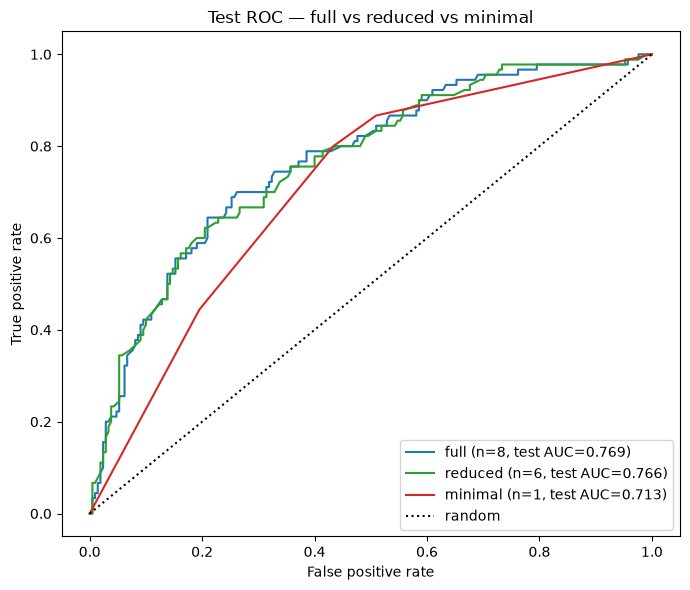

In [126]:
fig, ax = plt.subplots(figsize=(7, 6))
for name, color in [("full", "tab:blue"),
                    ("reduced", "tab:green"),
                    ("minimal", "tab:red")]:
    r = results[name]
    fpr, tpr, _ = roc_curve(test["bad"], r["p_test"])
    ax.plot(fpr, tpr, color=color,
            label=f"{name} (n={len(datasets[name]['vars'])}, test AUC={r['auc_test']:.3f})")

ax.plot([0, 1], [0, 1], "k:", label="random")
ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate")
ax.set_title("Test ROC — full vs reduced vs minimal")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

#### ROC curve : chosen model

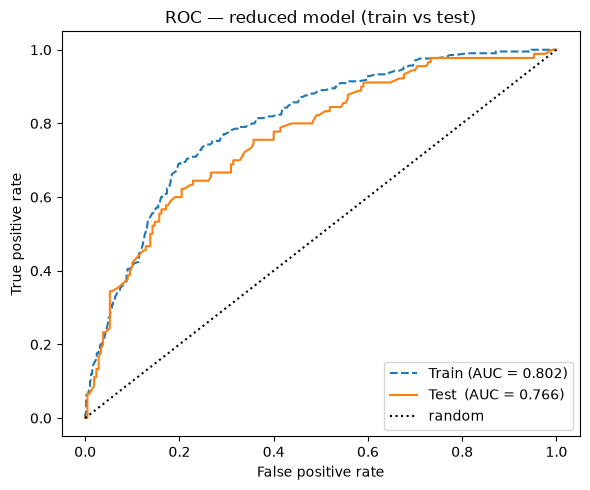

In [125]:
r = results[chosen]
fig, ax = plt.subplots(figsize=(6, 5))

fpr_tr, tpr_tr, _ = roc_curve(train["bad"], r["p_train"])
ax.plot(fpr_tr, tpr_tr, "--", color="tab:blue",
        label=f"Train (AUC = {r['auc_train']:.3f})")

fpr_te, tpr_te, _ = roc_curve(test["bad"], r["p_test"])
ax.plot(fpr_te, tpr_te, "-", color="tab:orange",
        label=f"Test  (AUC = {r['auc_test']:.3f})")

ax.plot([0, 1], [0, 1], "k:", label="random")
ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate")
ax.set_title(f"ROC — {chosen} model (train vs test)")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()


1. ROC plot.

2. **Model performance :**
-  Train AUC = 0.8019, Test AUC = 0.7657. Well above a random classifier (~50%) and separates good from bad credits well. 
- The area under the curve can also represents the probability that a randomly selected positive instance will be ranked higher by a classifier than a randomly selected negative instance [source - Hanley and McNeil, 1983]
- If our model was perfect, every bad would be scored above every good (AUC=1.0). If it was random (AUC=0.5).
- AUC=0.77 means: if we pick a random bad credit and a random good credit, the model ranks the bad one higher ~77 % of the time.



3. **Overfitting check.** 
- The gap is only `0.036`. We would need to be concerned around a 0.05 gap threshold for overfitting, so the model generalises cleanly to unseen applications. 
- We also have a few parameters (6) against rows (700), small model for plenty of data.
- From our binning strategy, no cells are  below n=35, so no tiny cells dictate our coefficients, so we force the model to generalize.
- Our `minimal` dataset even had a negative gap (−0.007). A negative gap (test AUC slightly higher than train AUC) can never come from overfitting. Overfitting means train > test. On a 300-row test set, ±0.01 AUC swings are just sampling noise. So the negative gap confirms the model isn't memorising : if it were, we would have a big positive gap. 


4. **Conclusion for the bank.** 
- The model can rank creditors really well (AUC 0.77), so the bank can use this model to prioritize reviews for at-risk applicants.
- It separates good applicants from bad applicants well. Picking a random bad and a random good, the bad gets the higher score ~77 % of the time.

4. **Limitation.** 
- The dataset is small (~700 training rows) and limited to a single bank's few year of data (South German Credit, 1973–1975), so the model's coefficients reflects a quite old and specific to this bank's data. 
- More recent data, from different banks would be needed before deployment. 
- Additionally, AUC measures *ranking*, not *calibration* :
- Ranking : the model can correctly separate good from bad ones, this helps the bank to prioritize who to review.
- Calibration : the probabilities our model predicts are not guaranteed to be correct, so the bank cannot currently use this model to decide what interest rate to charge for example.



#### Coefficients check

In [124]:
chosen = "reduced"

rows = []
for var, coef in zip(datasets[chosen]["vars"],
                     results[chosen]["model"].coef_[0]):
    tab       = woe_tables[var]
    lvl_col   = "level" if "level" in tab.columns else f"{var}_lvl"
    woe_min   = tab["woe"].min()
    woe_max   = tab["woe"].max()
    woe_range = woe_max - woe_min
    iv        = tab["iv_contrib"].sum()
    rows.append({
        "variable":    var,
        "coefficient": coef,
        "woe_min":     round(woe_min,   3),
        "woe_max":     round(woe_max,   3),
        "woe_range":   round(woe_range, 3),
        "effect":      round(abs(coef) * woe_range, 3),   # total log-odds swing
        "IV":          round(iv,        3),
    })

coefs = (pd.DataFrame(rows)
           .sort_values("effect", ascending=False)
           .reset_index(drop=True))

display(coefs)
print("\nIntercept:", round(results[chosen]["model"].intercept_[0], 4))

,variable,coefficient,woe_min,woe_max,woe_range,effect,IV
0,duration,-0.880823,-0.733,1.232,1.965,1.731,0.243
1,credit_history,-0.769864,-1.215,1.004,2.219,1.709,0.395
2,status,-0.809017,-0.816,1.128,1.944,1.573,0.650
3,property,-0.741741,-0.612,0.503,1.115,0.827,0.132
4,savings,-0.778986,-0.265,0.791,1.056,0.823,0.206
5,employment_duration,-0.901658,-0.431,0.359,0.791,0.713,0.106



Intercept: -0.8478


**Notes :**
- In Linear regression, the coefficients are easy to interpret (simple linear relation).
- In Logistic Regression, +1 in the coefficient increases the log-odds.
- Usually we'd need to exponentiate the coefficients because the log-scale is hard to interpret.
- but WOE is already on a log-odds scale, so β = 1 means the model uses WoE signal at full strength, at β=0, the model ignores the variable.
- Our coefficients all sit around −0.8, the model uses each WOE signal at roughly 80 % of its raw strength. It doesn't use them at 100 % because the six predictors overlap (status & savings both measure financial health; duration & credit_history both measure reliability), so the model spreads the credit across them.


why are coefficients all negative ? 
- we are trying to predict `P(bad)`, so increasing WoE (going to a safer level) should lower P(bad), hence the negative coefficients. All coefficients are expected to be negative

why is `employement_duration` coefficient higher than status (since its our highest IV predictor) ? 
- coefficient magnitude doesn't alone mean better predictor. We also have to look at our WoE range.
- looking at it, `employement_duration` has the lowest range, and its effect is the lowest of all our variables.

How to read the table : 
- Coefficient = how much the model trust uses variable's WOE.
- WOE range = how many units are available to push predictions.
- effect = coefficient × WOE range = actual prediction swing.
- IV ranks similarly to effect — both measure total separation across the variable's range — which is why the two columns trend together.



Intercept :
- The intercept is the log-odds when every WOE = 0, i.e. when every variable is at its "neutral" level (goods and bads equally represented).
- Converted to probability : P(bad | all WOE = 0) = 1 / (1 + exp(0.848)) = 1 / (1 + 2.335) = `0.30`. That matches the training base rate (30 % bad).


## 3. Construct the scorecard

Convert your model from Question 2 into a scorecard: a table of points that can be added to
obtain a credit score.



1. Create a table where each row is (variable, level, points). Sum of points = score.
2. 
3. Verify that your hand-built scorecard reproduces the model.
4. "Boxplots of test scores, good vs bad, highlight 2 cases"



Not needed :
- cross validation ? q2 handled overfitting already
- AIC or BIC ? Not asked, and we don't compare competing model families
- Confusion matrix ? Needs a threshold, and Q2 already covered AUC
- CAP Curve ? Alternative to ROC, redundant
- Accuracy ratio (GINI) ? Optionnal, Gini is the standard credit-scoring metric alongside AUC
- KS distance ? Another credit metric, not asked
- Lift Curve ? Marketing metric, not credit





### 3.1. Construct and check the scorecard

Create the full scorecard with columns predictor, level and points, using the approach discussed
in the lectures. Use these scale specifications:
- A score of 600 corresponds to good:bad odds of 50:1.
- Each 20-point increase doubles the good:bad odds (PDO = 20).

Higher scores therefore indicate lower predicted risk. For every test observation, compare the
total from your scorecard with the score implied by its model probability. Verify both scale
specifications. Keep your derivation, checks and explanation of any differences in the notebook.

#### Scorecards :
- A scorecard is a simple lookup table that loaners use to score applicants.
- Each variable gets a score, if the applicant fits it, we add this score to the total amount.
- The total amount is then compared to a treshold, e.g. if above 450 the applicant is automatically approved, if less he needs to be reviewed.
- This is better than the model running on the computer for several reasons: 
- Any loaner can do it by hand, they don't need the computer, Python knowledge, WoE mappings...
- Immediate explanation of why an applicant was rejected
- Can easily compare between applicants using their score, easier than compare probabilities

So the bank translates the model into a scorecard, its the same prediction, but done easier.


Step 1: Determine the scorecard scale
- our fitted model now spits out log-odds of a customer being a bad creditor. (e.g. -2.44 for safe and +1.20 for risky).
- But these numbers are not bounded, hard to read for humans and hard to explain.
- We need to convert those log-odds into scores.

```bash
Score = offset + factor x ln(good:bad Odds)
```

The bank asks us for a scorecard that : 
- (a) Good/Bad odds should be equal to 50/1 at score 600
- (b) Good/Bad odds are to double every 20 points


In [130]:
# Step 1: Determine the scorecard scale
#       Two design choices from the bank:
#         - (a) score 600 has good:bad odds 50:1
#         - (b) PDO = 20 points to double the odds
BASE_SCORE = 600
BASE_ODDS  = 50.0          # good:bad
PDO        = 20.0

In [ ]:
# Step 2: Calculate the 𝐨𝐟𝐟𝐬𝐞𝐭 and 𝐟𝐚𝐜𝐭𝐨𝐫

# (b) : +20pts double the score.
#       (1) : score_50  = offset + factor * ln(50)
#       (2) : score_100 = offset + factor * ln(100)
#       (2 - 1) : PDO  = factor * ( ln(100) - ln(50) )
#               : PDO  = factor * ln(2)  ---> (solve for factor)
Factor = PDO / np.log(2)

# (a):  at score=600 we want odds 50:1
#       BASE_SCORE = offset + factor* ln(BASE_ODDS)
#       <=> offset = ...
Offset = BASE_SCORE - Factor * np.log(BASE_ODDS)

print(f"Factor = {Factor:.4f}  (points per unit of ln-odds)")
print(f"Offset = {Offset:.4f}  (score when ln-odds = 0, i.e. odds = 1)")
print(f"\nScore formula: Score = {Offset:.2f} + {Factor:.4f} * ln(good:bad odds)")

Factor = 28.8539  (points per unit of ln-odds)
Offset = 487.1229  (score when ln-odds = 0, i.e. odds = 1)

Score formula: Score = 487.12 + 28.8539 * ln(good:bad odds)


In [ ]:
# Step 3: Plug in the logistic regression model




In [ ]:
# Step 4: Calculate points for characteristic levels




### 3.2. Visualize the scores

Create one figure with two boxplots of the test scores: one for observations with a good
outcome and one for observations with a bad outcome. Highlight these two cases:
- The highest-scoring bad observation.
- The lowest-scoring good observation.

In [115]:
# Your complete scorecard and verification on the test sample.

In [116]:
# Your test-score boxplots and the two highlighted cases.

**Submission:** run all cells in order, check results and save with outputs. Email the notebook and report PDF to **andreas.goethals@kuleuven.be** by **10 November 2026, 23:59 Belgian time**.

Subject: `DSFB_A1_r1_r2`. Files: `A1_r1_r2.pdf` and `A1_r1_r2.ipynb`. Use your actual r-numbers, smaller first. Follow all guidelines on page 1.
